<a href="https://colab.research.google.com/github/nehasinghrscse26-pixel/CS-7025_STAI/blob/main/STAI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Phase 1

In [ ]:
from pathlib import Path
import io, json, hashlib, zipfile, sys, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, joblib
import sklearn

In [ ]:
from scipy.stats import ks_2samp
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

In [ ]:
ROOT = Path('/content/model_extraction_phase1') if Path('/content').exists() else Path.cwd() / 'model_extraction_phase1'
DATA_DIR = ROOT / 'data'
OUT = ROOT / 'results_real'
MODEL_DIR = OUT / 'models'
for folder in (DATA_DIR, OUT, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)
print('Project:', ROOT)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Project: /content/model_extraction_phase1
Python: 3.13.18 | scikit-learn: 1.6.1


In [ ]:
UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
CSV_PATH = DATA_DIR / 'bank-additional-full.csv'

In [ ]:
def extract_full_csv(content: bytes) -> bytes:
    with zipfile.ZipFile(io.BytesIO(content)) as outer:
        names = outer.namelist()
        direct = next((n for n in names if n.lower().endswith('bank-additional-full.csv')), None)
        if direct:
            return outer.read(direct)
        nested = next((n for n in names if n.lower().endswith('bank-additional.zip')), None)
        if nested is None:
            raise ValueError(f'Full CSV not found in ZIP: {names[:10]}')
        with zipfile.ZipFile(io.BytesIO(outer.read(nested))) as inner:
            entry = next((n for n in inner.namelist() if n.lower().endswith('bank-additional-full.csv')), None)
            if entry is None:
                raise ValueError('Full CSV missing inside bank-additional.zip')
            return inner.read(entry)

if not CSV_PATH.exists():
    try:
        response = requests.get(UCI_ZIP_URL, timeout=90)
        response.raise_for_status()
        assert len(response.content) < 25_000_000, 'Unexpectedly large archive'
        CSV_PATH.write_bytes(extract_full_csv(response.content))
        print('Downloaded from UCI:', CSV_PATH)
    except Exception as err:
        print('Automatic download failed:', err)
        print('Visit https://archive.ics.uci.edu/dataset/222/bank+marketing and upload the official ZIP or bank-additional-full.csv.')
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError('Manually place the official bank-additional-full.csv at '+str(CSV_PATH)) from err
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise RuntimeError('Upload exactly one official ZIP or full CSV')
        filename, content = next(iter(uploaded.items()))
        if filename.lower().endswith('.zip'):
            CSV_PATH.write_bytes(extract_full_csv(content))
        elif filename.lower().endswith('bank-additional-full.csv'):
            CSV_PATH.write_bytes(content)
        else:
            raise ValueError('Use official bank+marketing.zip or bank-additional-full.csv')

df = pd.read_csv(CSV_PATH, sep=';', keep_default_na=False)
assert len(df) == 41188, f'Expected 41,188 rows, found {len(df)}; use FULL file'
assert {'y','duration','age','job','month','day_of_week'}.issubset(df.columns)
assert set(df['y'].unique()) <= {'no','yes'}
DATA_SHA = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
print('VALID REAL DATA | Rows:', len(df), '| columns:', len(df.columns))
print('SHA-256:', DATA_SHA[:24] + '…')
print('Positive (yes) rate:', round((df['y']=='yes').mean(),4))
display(df.head(3))

VALID REAL DATA | Rows: 41188 | columns: 21
SHA-256: 74adfc578bf77a7ff4bb1ba4…
Positive (yes) rate: 0.1127


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
n = len(df)
cuts = [0, int(.50*n), int(.65*n), int(.80*n), n]
split_names = ['victim_train','query_pool','older_test','later_test']
ids = {name: np.arange(cuts[i], cuts[i+1]) for i,name in enumerate(split_names)}

X = df.drop(columns=['y','duration']).copy()  # duration is unavailable before the call
y = (df['y']=='yes').astype(int)

partition_rows = []
for part, index in ids.items():
    partition_rows.append({'partition':part,'records':len(index),
                           'first_original_row':int(index[0]),'last_original_row':int(index[-1]),
                           'yes_rate':round(float(y.iloc[index].mean()),4)})
manifest = pd.DataFrame(partition_rows)
manifest.to_csv(OUT/'split_summary.csv',index=False)
pd.DataFrame({'original_row_id':np.arange(n),
              'partition':np.select([np.isin(np.arange(n),v) for v in ids.values()],
                                    list(ids.keys()), default='unknown'),
              'y':y}).to_csv(OUT/'partition_manifest.csv',index=False)
display(manifest)

,partition,records,first_original_row,last_original_row,yes_rate
0,victim_train,20594,0,20593,0.0468
1,query_pool,6178,20594,26771,0.0529
2,older_test,6178,26772,32949,0.1311
3,later_test,8238,32950,41187,0.3083


In [ ]:
numerical_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in X.columns if c not in numerical_cols]

numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', MinMaxScaler(feature_range=(-1,1), clip=False)),
])
category_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocess = ColumnTransformer([
    ('num',numeric_pipe,numerical_cols),
    ('cat',category_pipe,categorical_cols),
], sparse_threshold=.3)
print('Numerical:',len(numerical_cols), '| Categorical:',len(categorical_cols))
print('Dropped duration feature for realistic pre-call prediction.')

Numerical: 9 | Categorical: 10
Dropped duration feature for realistic pre-call prediction.


In [ ]:
estimators = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'Decision Tree': DecisionTreeClassifier(max_depth=7, min_samples_leaf=25, random_state=SEED),
    'Shallow MLP': MLPClassifier(hidden_layer_sizes=(24,), max_iter=220,
                                 early_stopping=True,n_iter_no_change=12,random_state=SEED),
    'Majority Baseline': DummyClassifier(strategy='most_frequent'),
}

trained = {}
for name, estimator in estimators.items():
    model = Pipeline([('preprocess', clone(preprocess)),('model',estimator)])
    model.fit(X.iloc[ids['victim_train']], y.iloc[ids['victim_train']])
    trained[name] = model
    filename = name.lower().replace(' ','_')+'.joblib'
    joblib.dump({
        'pipeline':model,
        'feature_names':X.columns.tolist(),
        'target_encoding':{'no':0,'yes':1},
        'training_split':'victim_train',
        'dataset_sha256':DATA_SHA,
        'model_name':name,
    }, MODEL_DIR/filename)
    print('Trained & saved:',name)

print('Saved model files:',len(list(MODEL_DIR.glob('*.joblib'))))

Trained & saved: Logistic Regression
Trained & saved: Decision Tree
Trained & saved: Shallow MLP
Trained & saved: Majority Baseline
Saved model files: 4


,model,period,n,accuracy,f1_yes,recall_yes,roc_auc
1,Logistic Regression,older_test,6178,0.2517,0.2332,0.8679,0.4711
2,Logistic Regression,later_test,8238,0.2532,0.3475,0.6449,0.4040
4,Decision Tree,older_test,6178,0.8689,0.0000,0.0000,0.5683
5,Decision Tree,later_test,8238,0.6917,0.0000,0.0000,0.5582
7,Shallow MLP,older_test,6178,0.8689,0.0000,0.0000,0.4007
8,Shallow MLP,later_test,8238,0.6917,0.0000,0.0000,0.3520
10,Majority Baseline,older_test,6178,0.8689,0.0000,0.0000,0.5000
11,Majority Baseline,later_test,8238,0.6917,0.0000,0.0000,0.5000


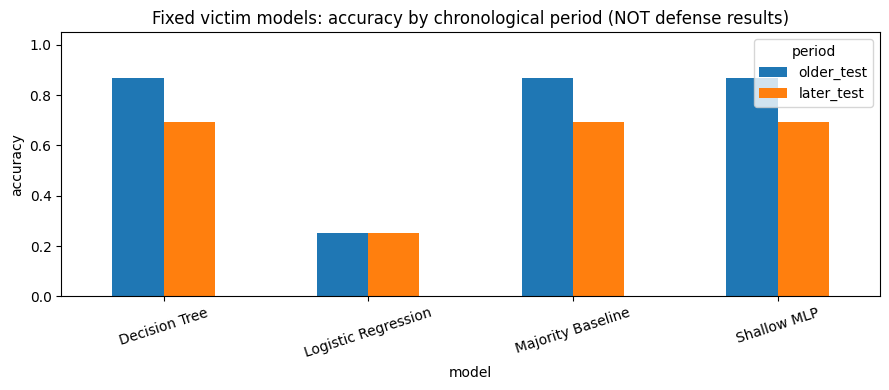

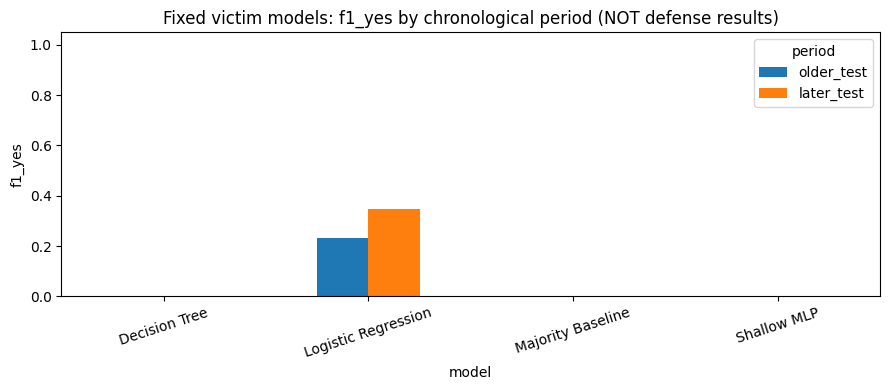

In [ ]:
def score_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:,1]
    cm = confusion_matrix(y_eval,pred,labels=[0,1])
    return {
        'accuracy':accuracy_score(y_eval,pred),
        'f1_yes':f1_score(y_eval,pred,zero_division=0),
        'precision_yes':precision_score(y_eval,pred,zero_division=0),
        'recall_yes':recall_score(y_eval,pred,zero_division=0),
        'roc_auc':roc_auc_score(y_eval,prob) if len(np.unique(y_eval))>1 else np.nan,
        'TN':int(cm[0,0]),'FP':int(cm[0,1]),'FN':int(cm[1,0]),'TP':int(cm[1,1]),
    }

records=[]
for model_name, model in trained.items():
    for part in ['victim_train','older_test','later_test']:
        idx=ids[part]
        records.append({'model':model_name,'period':part,'n':len(idx),
                        'positive_rate':y.iloc[idx].mean(),
                        **score_model(model,X.iloc[idx],y.iloc[idx])})

results = pd.DataFrame(records)
results.to_csv(OUT/'baseline_results.csv',index=False,float_format='%.6f')
display(results[results.period.isin(['older_test','later_test'])][
    ['model','period','n','accuracy','f1_yes','recall_yes','roc_auc']
].round(4))

for metric in ['accuracy','f1_yes']:
    sub=results[results.period.isin(['older_test','later_test'])]
    p=sub.pivot(index='model',columns='period',values=metric)
    ax=p[['older_test','later_test']].plot.bar(figsize=(9,4),rot=18)
    ax.set_ylabel(metric)
    ax.set_ylim(0,1.05)
    ax.set_title(f'Fixed victim models: {metric} by chronological period (NOT defense results)')
    plt.tight_layout()
    plt.savefig(OUT/f'{metric}_older_vs_later.png',dpi=160,bbox_inches='tight')
    plt.show()

,feature,type,method,difference,p_value,older_summary,later_summary
7,euribor3m,numeric,KS,0.9852,0.0,1.776322,1.030735
8,nr.employed,numeric,KS,0.6026,0.0,5113.437261,5054.625674
6,cons.conf.idx,numeric,KS,0.5623,0.0,-46.113758,-39.962867
16,month,categorical,Total variation,0.4784,NaN,may,may
4,emp.var.rate,numeric,KS,0.3528,0.0,-1.547556,-2.191782
5,cons.price.idx,numeric,KS,0.2950,0.0,93.008028,93.061537
17,day_of_week,categorical,Total variation,0.1707,NaN,fri,tue
9,job,categorical,Total variation,0.1664,NaN,blue-collar,admin.
2,pdays,numeric,KS,0.1393,0.0,975.682421,837.37497
18,poutcome,categorical,Total variation,0.1287,NaN,nonexistent,nonexistent


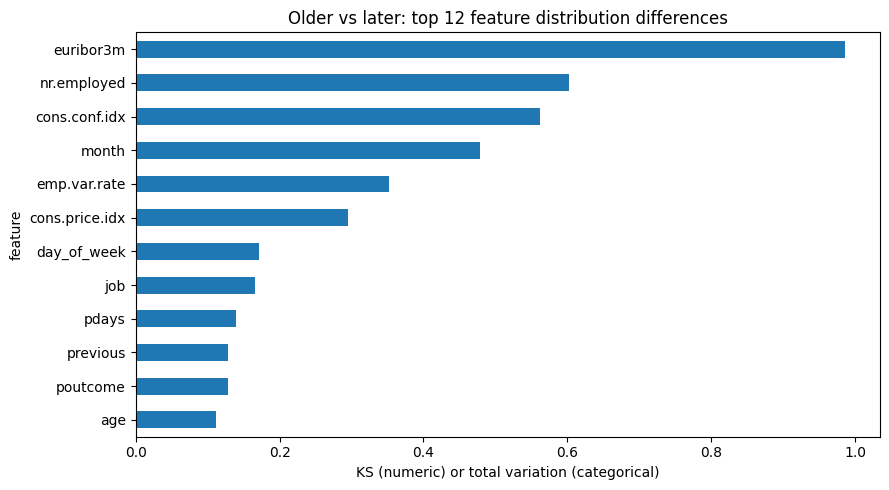

In [ ]:
older=X.iloc[ids['older_test']]
later=X.iloc[ids['later_test']]
drift=[]

for col in numerical_cols:
    a=pd.to_numeric(older[col],errors='coerce').dropna()
    b=pd.to_numeric(later[col],errors='coerce').dropna()
    if len(a) and len(b):
        res=ks_2samp(a,b)
        drift.append({'feature':col,'type':'numeric','method':'KS',
                      'difference':float(res.statistic),'p_value':float(res.pvalue),
                      'older_summary':float(a.mean()),'later_summary':float(b.mean())})

for col in categorical_cols:
    p=older[col].astype(str).value_counts(normalize=True)
    q=later[col].astype(str).value_counts(normalize=True)
    idx=p.index.union(q.index)
    tv=0.5*(p.reindex(idx,fill_value=0)-q.reindex(idx,fill_value=0)).abs().sum()
    drift.append({'feature':col,'type':'categorical','method':'Total variation',
                  'difference':float(tv),'p_value':np.nan,
                  'older_summary':older[col].astype(str).mode().iat[0],
                  'later_summary':later[col].astype(str).mode().iat[0]})

drift_df=pd.DataFrame(drift).sort_values('difference',ascending=False)
drift_df.to_csv(OUT/'drift_summary.csv',index=False,float_format='%.6f')
display(drift_df.head(12).round(4))

ax=drift_df.head(12).sort_values('difference').plot.barh(x='feature',y='difference',legend=False,figsize=(9,5))
ax.set_title('Older vs later: top 12 feature distribution differences')
ax.set_xlabel('KS (numeric) or total variation (categorical)')
plt.tight_layout()
plt.savefig(OUT/'drift_differences.png',dpi=160,bbox_inches='tight')
plt.show()

In [ ]:
sample_record = X.iloc[int(ids['query_pool'][0])].to_dict()
with open(OUT/'sample_api_input.json','w',encoding='utf8') as f:
    json.dump({'features':sample_record},f,indent=2,default=str)

summary = {
 'project':'Model Extraction Research — Phase 1 Victim Model Baselines and Drift Analysis',
 'data_source':'UCI Bank Marketing official bank-additional-full.csv',
 'data_sha256':DATA_SHA,'n_records':len(df),'n_features_used':len(X.columns),
 'feature_columns':X.columns.tolist(),'dropped_post_call':['duration'],
 'split_summary':manifest.to_dict(orient='records'),
 'older_yes_rate':float(y.iloc[ids['older_test']].mean()),
 'later_yes_rate':float(y.iloc[ids['later_test']].mean()),
 'random_state':SEED,'python_version':sys.version.split()[0],
 'sklearn_version':sklearn.__version__,
 'notes':['Original row order used as chronological proxy; no exact year labels.',
          'Only victim_train used for fitting victim models and their preprocessors.',
          'Drift check compares input distributions; it is not concept drift proof.',
          'API defenses and extracted surrogate evaluations are not part of Phase 1.']
}
with open(OUT/'run_summary.json','w',encoding='utf8') as f:
    json.dump(summary,f,indent=2)

for name in ['Logistic Regression','Decision Tree','Shallow MLP']:
    path=MODEL_DIR/(name.lower().replace(' ','_')+'.joblib')
    loaded=joblib.load(path)  # load ONLY notebook-generated, trusted joblib files
    pred_before=trained[name].predict(X.iloc[ids['older_test'][:5]])
    pred_after=loaded['pipeline'].predict(X.iloc[ids['older_test'][:5]])
    assert np.array_equal(pred_before,pred_after)
print('PASS: Saved models reload correctly and reproduce example predictions.')
print('Outputs are saved under:', OUT)
print('Generated files:', ', '.join(sorted(p.name for p in OUT.iterdir())))

PASS: Saved models reload correctly and reproduce example predictions.
Outputs are saved under: /content/model_extraction_phase1/results_real
Generated files: accuracy_older_vs_later.png, baseline_results.csv, drift_differences.png, drift_summary.csv, f1_yes_older_vs_later.png, models, partition_manifest.csv, run_summary.json, sample_api_input.json, split_summary.csv


The UCI Bank Marketing dataset is partitioned chronologically into victim training, a query pool, and older and later evaluation sets. The post-contact duration feature is excluded to avoid leakage. Preprocessing is fitted on the victim-training partition only, then Logistic Regression, Decision Tree, and MLP models are trained and saved. Evaluation reports accuracy, F1, recall, and ROC-AUC, alongside KS and total-variation statistics for input-distribution drift. These Phase 1 outputs can now be integrated into the trusted prediction API and subsequent extraction experiments. Defense effectiveness has not yet been evaluated.

Phase 2

In [ ]:
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from typing import Any, Dict, Optional
import threading
import time
import uvicorn
from fastapi.testclient import TestClient

print('FastAPI and Uvicorn are ready.')

FastAPI and Uvicorn are ready.


In [ ]:
API_HOST = '127.0.0.1'
API_PORT = 8000

DEFENSE_CONFIG = {
    'truncation_decimals': 3,
    'mask_label': False,
    'hide_probability': False,
    'noise_delta': 0.02,
}

assert DEFENSE_CONFIG['truncation_decimals'] is None or 0 <= DEFENSE_CONFIG['truncation_decimals'] <= 8
assert 0.0 <= DEFENSE_CONFIG['noise_delta'] <= 0.5
print('Active defense configuration:', DEFENSE_CONFIG)

Active defense configuration: {'truncation_decimals': 3, 'mask_label': False, 'hide_probability': False, 'noise_delta': 0.02}


In [ ]:
API_MODELS = {}
for model_name in ['Logistic Regression', 'Decision Tree', 'Shallow MLP']:
    model_file = MODEL_DIR / (model_name.lower().replace(' ', '_') + '.joblib')
    if not model_file.exists():
        raise FileNotFoundError(f'Missing {model_file}. Run Phase 1 model-training cell first.')
    bundle = joblib.load(model_file)
    if bundle['feature_names'] != X.columns.tolist():
        raise ValueError(f'Feature schema mismatch for {model_name}')
    API_MODELS[model_name] = bundle['pipeline']

API_FEATURES = X.columns.tolist()
print('Models available to API:', list(API_MODELS))
print('Expected feature count:', len(API_FEATURES))

Models available to API: ['Logistic Regression', 'Decision Tree', 'Shallow MLP']
Expected feature count: 19


In [ ]:
class PredictionRequest(BaseModel):
    model_name: str = Field(default='Logistic Regression')
    features: Dict[str, Any]

def apply_output_defenses(raw_probability: float, config: dict) -> dict:
    """Apply output-side defenses to P(yes), without changing the victim model."""
    defended_probability = float(raw_probability)

    delta = float(config.get('noise_delta', 0.0))
    if delta > 0:
        epsilon = float(np.random.uniform(-delta, delta))
        defended_probability = defended_probability + epsilon
    else:
        epsilon = 0.0

    defended_probability = float(np.clip(defended_probability, 0.0, 1.0))

    decimals = config.get('truncation_decimals', None)
    if decimals is not None:
        defended_probability = float(np.round(defended_probability, int(decimals)))

    predicted_label = 'yes' if defended_probability >= 0.5 else 'no'
    if bool(config.get('mask_label', False)):
        predicted_label = None

    return {
        'probability_yes': defended_probability,
        'prediction': predicted_label,
        'noise_epsilon': epsilon,
    }

def create_mlaas_app(models: dict, feature_names: list, defense_config: dict) -> FastAPI:
    app = FastAPI(
        title='Local Model-as-a-Service (MLaaS)',
        description='Research API for testing prediction-output defenses on tabular victim models.',
        version='1.0.0',
    )

    @app.get('/health')
    def health():
        return {'status': 'ok', 'models': list(models.keys())}

    @app.get('/models')
    def list_models():
        return {'available_models': list(models.keys()), 'feature_count': len(feature_names)}

    @app.post('/predict')
    def predict(request: PredictionRequest):
        if request.model_name not in models:
            raise HTTPException(status_code=404, detail=f"Unknown model. Choose one of: {list(models.keys())}")

        supplied = set(request.features.keys())
        expected = set(feature_names)
        missing = sorted(expected - supplied)
        extra = sorted(supplied - expected)
        if missing or extra:
            raise HTTPException(
                status_code=422,
                detail={'missing_features': missing, 'unexpected_features': extra},
            )

        record = pd.DataFrame(
            [[request.features[name] for name in feature_names]],
            columns=feature_names,
        )
        try:
            raw_probability = float(models[request.model_name].predict_proba(record)[0, 1])
        except Exception as exc:
            raise HTTPException(status_code=422, detail=f'Input could not be processed: {exc}')

        defended = apply_output_defenses(raw_probability, defense_config)

        defended = apply_output_defenses(raw_probability, defense_config)

        response = {
            'model_name': request.model_name,
            'prediction': defended['prediction'],
            'defenses': {
                'truncation_decimals': defense_config.get('truncation_decimals'),
                'label_masking': bool(defense_config.get('mask_label', False)),
                'probability_masking': bool(defense_config.get('hide_probability', False)),
                'bounded_noise_delta': float(defense_config.get('noise_delta', 0.0)),
            }
        }

        if not defense_config.get('hide_probability', False):
            response['probability_yes'] = defended['probability_yes']

        return response


    return app

app = create_mlaas_app(API_MODELS, API_FEATURES, DEFENSE_CONFIG)
print('FastAPI app created. Routes:', [route.path for route in app.routes])

FastAPI app created. Routes: ['/openapi.json', '/docs', '/docs/oauth2-redirect', '/redoc', '/health', '/models', '/predict']


In [ ]:
test_client = TestClient(app)

health_response = test_client.get('/health')
assert health_response.status_code == 200, health_response.text
print('Health:', health_response.json())

sample_api_record = X.iloc[int(ids['query_pool'][0])].to_dict()
payload = {'model_name': 'Logistic Regression', 'features': sample_api_record}
prediction_response = test_client.post('/predict', json=payload)
assert prediction_response.status_code == 200, prediction_response.text
print('Prediction response:', prediction_response.json())

bad_payload = {'model_name': 'Logistic Regression', 'features': {'age': 35}}
bad_response = test_client.post('/predict', json=bad_payload)
assert bad_response.status_code == 422
print('PASS: API returns 422 for incomplete feature records.')

Health: {'status': 'ok', 'models': ['Logistic Regression', 'Decision Tree', 'Shallow MLP']}
Prediction response: {'model_name': 'Logistic Regression', 'prediction': 'no', 'defenses': {'truncation_decimals': 3, 'label_masking': False, 'probability_masking': False, 'bounded_noise_delta': 0.02}, 'probability_yes': 0.086}
PASS: API returns 422 for incomplete feature records.


In [ ]:
if 'api_thread' not in globals() or not api_thread.is_alive():

    server_config = uvicorn.Config(
        app,
        host=API_HOST,
        port=API_PORT,
        log_level='warning'
    )

    api_server = uvicorn.Server(server_config)

    api_thread = threading.Thread(
        target=api_server.run,
        daemon=True
    )

    api_thread.start()

    for _ in range(40):
        try:
            health = requests.get(
                f'http://{API_HOST}:{API_PORT}/health',
                timeout=1
            )

            if health.ok:
                break

        except requests.RequestException:
            time.sleep(0.25)

    else:
        raise RuntimeError(
            'FastAPI server did not start. '
            'Check whether the port is in use.'
        )

else:
    print("FastAPI server is already running.")

API_BASE_URL = f'http://{API_HOST}:{API_PORT}'

print('Local MLaaS server:', API_BASE_URL)

print(
    'Health check:',
    requests.get(API_BASE_URL + '/health', timeout=5).json()
)


FastAPI server is already running.
Local MLaaS server: http://127.0.0.1:8000
Health check: {'status': 'ok', 'models': ['Logistic Regression', 'Decision Tree', 'Shallow MLP']}


In [ ]:
http_response = requests.post(
    API_BASE_URL + '/predict',
    json=payload,
    timeout=15,
)
print('HTTP status:', http_response.status_code)
print('API output:', http_response.json())
http_response.raise_for_status()

phase2_summary = {
    'phase': 'Phase 2 — Local FastAPI MLaaS and API output defenses',
    'host': API_HOST,
    'port': API_PORT,
    'available_models': list(API_MODELS.keys()),
    'feature_count': len(API_FEATURES),
    'defense_config': DEFENSE_CONFIG,
    'example_http_status': http_response.status_code,
    'example_response': http_response.json(),
    'definitions': {
        'truncation': 'Round returned P(yes) to truncation_decimals decimal places.',
        'label_masking': 'Hide the predicted yes/no class label in the response.',
        'bounded_noise': 'Add epsilon ~ Uniform(-delta, delta) to P(yes), then clip to [0,1].',
    },
    'limitations': [
        'This is a local research prototype, not a production-hardened service.',
        'Bounded noise is not by itself a differential-privacy guarantee.',
        'The API deliberately does not expose the raw model probability.',
        'The returned score and label can vary between repeated requests when noise is enabled.',
    ],
}
with open(OUT / 'phase2_api_summary.json', 'w', encoding='utf-8') as f:
    json.dump(phase2_summary, f, indent=2)
print('Saved:', OUT / 'phase2_api_summary.json')

HTTP status: 200
API output: {'model_name': 'Logistic Regression', 'prediction': 'no', 'probability_yes': 0.061, 'defenses': {'truncation_decimals': 3, 'label_masking': False, 'bounded_noise_delta': 0.02}}
Saved: /content/model_extraction_phase1/results_real/phase2_api_summary.json


In [ ]:
import requests

BASE_URL = "http://127.0.0.1:8000"

response = requests.get(BASE_URL + "/health")
print(response.status_code)
print(response.json())

response = requests.get(BASE_URL + "/models")
print(response.json())

200
{'status': 'ok', 'models': ['Logistic Regression', 'Decision Tree', 'Shallow MLP']}
{'available_models': ['Logistic Regression', 'Decision Tree', 'Shallow MLP'], 'feature_count': 19}


In [ ]:
from fastapi.testclient import TestClient
import pandas as pd

experiments = {
    "Baseline": {
        "truncation_decimals": None,
        "mask_label": False,
        "hide_probability": False,
        "noise_delta": 0.0
    },
    "Truncation": {
        "truncation_decimals": 1,
        "mask_label": False,
        "hide_probability": False,
        "noise_delta": 0.0
    },
    "Probability Masking": {
        "truncation_decimals": None,
        "mask_label": False,
        "hide_probability": True,
        "noise_delta": 0.0
    },
    "Bounded Noise": {
        "truncation_decimals": None,
        "mask_label": False,
        "hide_probability": False,
        "noise_delta": 0.05
    },
    "Combined": {
        "truncation_decimals": 1,
        "mask_label": False,
        "hide_probability": True,
        "noise_delta": 0.05
    }
}

sample_record = X.iloc[int(ids['query_pool'][0])].to_dict()

experiment_results = []

for experiment_name, config in experiments.items():

    test_app = create_mlaas_app(
        API_MODELS,
        API_FEATURES,
        config
    )

    client = TestClient(test_app)

    payload = {
        "model_name": "Logistic Regression",
        "features": sample_record
    }

    response = client.post("/predict", json=payload)

    assert response.status_code == 200, response.text

    result = response.json()

    experiment_results.append({
        "Experiment": experiment_name,
        "Probability": result.get("probability_yes", "HIDDEN"),
        "Prediction": result["prediction"],
        "Status": response.status_code
    })

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df)

experiment_df.to_csv(
    OUT / "phase2_defense_smoke_tests.csv",
    index=False
)

print("All defense configurations tested successfully.")

,Experiment,Probability,Prediction,Status
0,Baseline,0.072552,no,200
1,Truncation,0.1,no,200
2,Probability Masking,HIDDEN,no,200
3,Bounded Noise,0.040893,no,200
4,Combined,HIDDEN,no,200


All defense configurations tested successfully.


The victim models implemented above were integrated into a local FastAPI-based Model-as-a-Service architecture. A prediction endpoint was developed to accept tabular feature records and return model predictions. Three output-level defense mechanisms—confidence precision reduction, label masking and bounded additive noise—were implemented as configurable middleware. The API was tested using health checks, model listing, valid and invalid prediction requests, and five different defense configurations. All functional tests completed successfully.

Current status: API implementation and initial functional testing completed. Quantitative defense effectiveness and model extraction resistance remain to be evaluated in Phase 3.